#  Main Pipeline: Patch Training + Stages 1-3 + Full Evaluation


In [25]:

import os
os.environ['PYTORCH_ENABLE_MPS_FALLBACK'] = '1'
import sys
sys.path.insert(0, os.path.abspath('.'))
import warnings
warnings.filterwarnings("ignore")

import torch
from src.config import (DEVICE, PATCH_PATH, THRESHOLD_PATH, RESULTS_DIR,
                         TARGET_CLASS, IMAGENETTE_TO_IMAGENET)
from src.model import get_model
from src.data_loader import (get_loaders, build_partition_indices,
                              get_partition, verify_clean_accuracy)
from src.attack import load_patch, apply_patch
from src.gradcam_defense import GradCAM

print(f"Device: {DEVICE}")
model      = get_model(eval_mode=True)
partitions = build_partition_indices()
print("Partition sizes:", {k: len(v) for k, v in partitions.items()})

train_loader, val_loader, test_loader = get_loaders(download=True)
clean_acc = verify_clean_accuracy(model, test_loader, max_batches=30)
assert clean_acc > 80, f"Clean accuracy too low: {clean_acc:.1f}%"
print(f"Clean accuracy: {clean_acc:.1f}%")


Device: mps
Partition sizes: {'stage1_bench': 250, 'fs_tuning': 500, 'fs_dev': 200, 'stage3_dev': 100, 'final_eval': 1000}
ImageNette already downloaded.
Train: 7,575  Val: 1,894  Test: 3,925


python(51266) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(51281) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(51286) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(51301) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.


 Clean accuracy: 99.8%  (958/960)
Clean accuracy: 99.8%


## Step 1: Train adversarial patch

In [26]:
# Skip if patch already trained
import os, torch
_path = 'results/patches/patch.pt'
if os.path.exists(_path):
    print("[SKIP] patch.pt exists -- loading.")
    patch = load_patch()   # load_patch() now prints only shape
else:
    print("[RUN] Training patch...")
    from src.attack import train_patch
    patch = train_patch(model, train_loader, steps=1000, save=True)
print(f"Patch shape: {tuple(patch.shape)}")


[SKIP] patch.pt exists -- loading.
Patch loaded  shape: (3, 89, 89)
Patch shape: (3, 89, 89)


### Visualise patch

python(51496) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(51511) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(51512) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(51517) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.


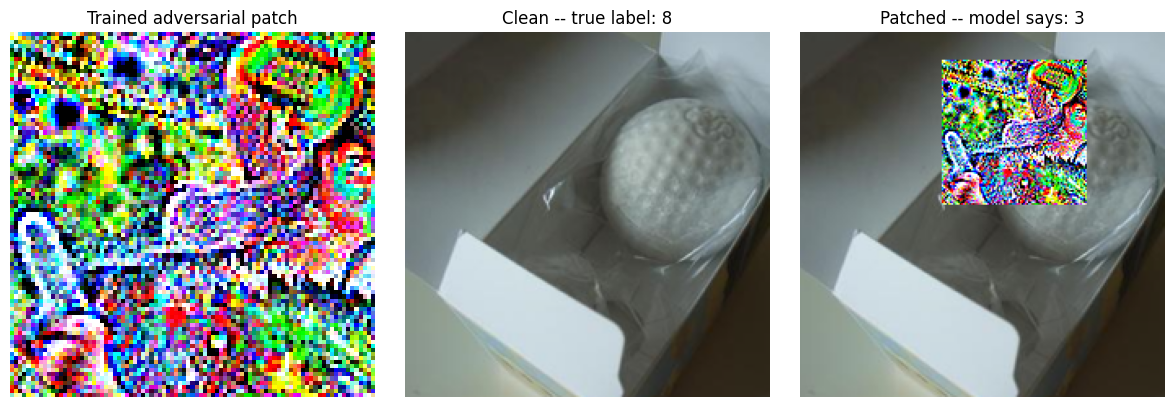

In [27]:

import matplotlib.pyplot as plt
from src.attack import apply_patch
from src.data_loader import denormalise

# Load a few images to visualise against
_images_vis, _labels_vis = get_partition("stage1_bench", partitions)
_patched_vis, _ = apply_patch(_images_vis[:1].clone(), patch, augment=False)

fig, axes = plt.subplots(1, 3, figsize=(12, 4))
axes[0].imshow(patch.cpu().permute(1,2,0).numpy())
axes[0].set_title('Trained adversarial patch'); axes[0].axis('off')
axes[1].imshow(denormalise(_images_vis[0]).cpu().permute(1,2,0).numpy())
axes[1].set_title(f'Clean -- true label: {_labels_vis[0].item()}'); axes[1].axis('off')
axes[2].imshow(denormalise(_patched_vis[0]).cpu().permute(1,2,0).numpy())
with torch.no_grad():
    pred = model(_patched_vis).argmax(1).item()
axes[2].set_title(f'Patched -- model says: {pred}'); axes[2].axis('off')
plt.tight_layout(); plt.show()


## Step 2: Stage 1  Classical detector benchmark

In [28]:

# Load stage1_bench partition (250 clean + 250 patched, disjoint from all others)
images_clean, labels = get_partition("stage1_bench", partitions)
images_patched, patch_positions = apply_patch(images_clean.clone(), patch, augment=False)
n_half = images_clean.size(0)
print(f"Stage 1 partition: {n_half} images")


python(51582) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(51583) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(51598) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(51599) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.


Stage 1 partition: 250 images


In [29]:

import cv2
print(f"OpenCV: {cv2.__version__}")
try:
    surf = cv2.xfeatures2d.SURF_create(hessianThreshold=400)
    print("SURF available")
except Exception as e:
    print(f"SURF unavailable: {e}")


OpenCV: 4.13.0
SURF unavailable: module 'cv2.xfeatures2d' has no attribute 'SURF_create'


In [30]:

from src.classical import detect_patch
for method in ["sift", "akaze", "orb"]:
    flag_c, _, info_c = detect_patch(images_clean[0], method=method)
    flag_p, _, info_p = detect_patch(images_patched[0], method=method)
    print(f"{method.upper():6s}  clean={flag_c} kp={info_c['n_keypoints']}  "
          f"patched={flag_p} kp={info_p['n_keypoints']}")


SIFT    clean=False kp=80  patched=True kp=165
AKAZE   clean=False kp=10  patched=True kp=112
ORB     clean=False kp=111  patched=True kp=390


In [31]:

# Skip if classical benchmark already done
import os, torch
_path = 'results/checkpoints/classical_results.pt'
if os.path.exists(_path):
    print("[SKIP] classical_results.pt exists -- loading.")
    classical_results = torch.load(_path, weights_only=False)
    for m, r in classical_results.items():
        print(f"  {m.upper():6s}: Detection={r['detection_rate']:.1f}%  "
              f"FPR={r['fpr']:.1f}%  Precision={r['precision']:.1f}%")
else:
    print("[RUN] Running classical benchmark...")
    from src.classical import benchmark_detectors
    classical_results = benchmark_detectors(images_clean, images_patched)


[SKIP] classical_results.pt exists -- loading.
  SIFT  : Detection=4.4%  FPR=4.0%  Precision=52.4%
  AKAZE : Detection=74.8%  FPR=23.2%  Precision=76.3%
  ORB   : Detection=96.0%  FPR=34.0%  Precision=73.8%


In [32]:

from src.classical import detect_patch
flag, bbox, info = detect_patch(images_patched[0], method="orb")
print(f"Patched: detected={flag}  bbox={bbox}")
flag, bbox, info = detect_patch(images_clean[0], method="orb")
print(f"Clean:   detected={flag}  bbox={bbox}")


Patched: detected=True  bbox=(84, 119, 182, 189)
Clean:   detected=False  bbox=None


In [33]:

from src.classical import visualise_detection
import random
idx = random.randint(0, n_half - 1)
for method in ['sift', 'orb', 'akaze']:
    visualise_detection(images_clean[idx], patch,
                        patch_pos=patch_positions[idx], method=method)
print("Detector comparison plots saved.")


Visualisation saved
Visualisation saved
Visualisation saved
Detector comparison plots saved.


## Step 3: Stage 2  Feature squeezing threshold tuning

In [34]:

# Load fs_tuning partition (500 images, disjoint from final_eval)
from src.feature_squeeze import evaluate_fs
images_clean, labels = get_partition("fs_tuning", partitions)
images_patched, _ = apply_patch(images_clean.clone(), patch, augment=False)
print(f"fs_tuning partition: {images_clean.size(0)} images")


python(51648) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(51663) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(51670) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(51685) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.


fs_tuning partition: 500 images


In [35]:

# Skip if threshold already tuned
import os, torch
_path = 'results/checkpoints/fs_threshold.pt'
if os.path.exists(_path):
    print("[SKIP] fs_threshold.pt exists -- loading.")
    from src.feature_squeeze import load_threshold
    fs_threshold = load_threshold()
else:
    print("[RUN] Tuning threshold...")
    from src.feature_squeeze import tune_threshold
    fs_threshold = tune_threshold(model, images_clean, images_patched, save=True)
print(f"Threshold: {fs_threshold:.3f}")
print("If this matches 0.150 from prior runs -> report as stability finding in Section III-D.")


[SKIP] fs_threshold.pt exists -- loading.
Threshold loaded: 0.150
Threshold: 0.150
If this matches 0.150 from prior runs -> report as stability finding in Section III-D.


In [36]:

# Sanity check on fs_dev partition (disjoint from fs_tuning and final_eval)
from src.data_loader import get_partition
from src.feature_squeeze import evaluate_fs
images_c, labels_c = get_partition("fs_dev", partitions)
images_p, _ = apply_patch(images_c.clone(), patch, augment=False)
fs_stats = evaluate_fs(model, images_c, images_p, fs_threshold)
print(f"Feature squeezing dev set -- Detection: {fs_stats['detection_rate']:.1f}%  "
      f"FPR: {fs_stats['fpr']:.1f}%")


python(51734) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(51749) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(51750) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(51768) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.


Threshold 0.150  Detection: 74.5%  FPR: 11.0%  Precision: 87.1%
Feature squeezing dev set -- Detection: 74.5%  FPR: 11.0%


## Step 4: Stage 3 GradCAM localization and masking

In [37]:

# Load stage3_dev partition (100 images, disjoint from all other sets)
gradcam = GradCAM(model, target_layer_name='layer4')
images_clean, labels = get_partition("stage3_dev", partitions)
images_patched, kp_positions = apply_patch(images_clean.clone(), patch, augment=False)
print(f"stage3_dev partition: {images_clean.size(0)} images")


python(51891) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(51906) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(51907) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(51922) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.


stage3_dev partition: 100 images


In [38]:

# Keypoint bboxes for Stage 3 intersection -- must use ORB (matches paper)
from src.classical import detect_patch_batch
_, kp_bboxes, _ = detect_patch_batch(images_patched, method='orb')
print(f"ORB bboxes found: {sum(b is not None for b in kp_bboxes)}/{len(kp_bboxes)}")


ORB bboxes found: 97/100


In [39]:

from src.gradcam_defense import reclassify_batch
gradcam_stats = reclassify_batch(
    model, gradcam, images_patched, labels,
    kp_bboxes=kp_bboxes, save_examples=True
)
print(f"GradCAM recovered: {gradcam_stats['recovered_acc']:.1f}%")


Processing 100 images...


Reclassifying: 100%|██████████| 100/100 [00:06<00:00, 15.06it/s]

Patched acc (before masking): 15.0%
Recovered acc (after masking): 98.0%
GradCAM recovered: 98.0%


## Step 5: Threshold stability check

In [43]:

# Non-destructive: checks theta on an independent sample without overwriting
from src.feature_squeeze import tune_threshold
from src.data_loader import build_partition_indices, get_partition, _PARTITION_SPEC

extended_spec = _PARTITION_SPEC + [("fs_stability_check", 500)]
stab_parts    = build_partition_indices(spec=extended_spec)
stab_clean, _ = get_partition("fs_stability_check", stab_parts)
stab_patched, _ = apply_patch(stab_clean.clone(), patch, augment=False)

stability_threshold = tune_threshold(model, stab_clean, stab_patched, save=False)
print(f"fs_tuning threshold:   {fs_threshold:.3f}")
print(f"Stability-check theta: {stability_threshold:.3f}")
if abs(stability_threshold - fs_threshold) < 1e-9:
    print("Identical -> report stability in Section III-D.")
else:
    print(f"Differs by {abs(stability_threshold-fs_threshold):.3f} -> note.")


python(52503) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(52522) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(52525) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(52526) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.


Computing scores on 500 clean + 500 patched images …
Best threshold: 0.100  Detection: 81.0%
fs_tuning threshold:   0.150
Stability-check theta: 0.100
Differs by 0.050 -> note.


## Step 6: Full 5-method evaluation on final_eval partition

In [44]:

# Load final_eval (1000 images, disjoint from ALL tuning sets)
gradcam = GradCAM(model, target_layer_name='layer4')
from src.feature_squeeze import load_threshold
fs_threshold = load_threshold()
images_clean, labels = get_partition("final_eval", partitions)
images_patched, _    = apply_patch(images_clean.clone(), patch, augment=False)
print(f"final_eval: {images_clean.size(0)} images  theta={fs_threshold:.3f}")


Threshold loaded: 0.150


python(52927) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(52944) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(52945) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(52965) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.


final_eval: 1000 images  theta=0.150


In [45]:

# Smoke test on 50 images before the full run
from src.pipeline import run_full_evaluation
test_results = run_full_evaluation(
    model, gradcam,
    images_clean[:50], images_patched[:50], labels[:50],
    fs_threshold, kp_method='orb', save=False
)
print("Smoke test (50 images):")
for m, r in test_results.items():
    print(f"  {m}: Clean={r['clean_acc']:.1f}%  Recovered={r['recovered_acc']:.1f}%  FPR={r['fpr']:.1f}%")



Evaluating: no defense
  Clean acc: 100.0% (95% CI: 100.0-100.0)
Evaluating: JPEG compression


  Clean acc: 100.0%  Recovered: 66.0%
Evaluating: feature squeezing only
  Detection rate: 78.0%  FPR: 12.0%
Evaluating: GradCAM only


  Clean acc: 98.0%  Recovered: 96.0%
 Evaluating: hybrid pipeline (all 3 stages)


  Recovered: 90.0%  FPR: 2.0%
Smoke test (50 images):
  no_defense: Clean=100.0%  Recovered=28.0%  FPR=0.0%
  jpeg: Clean=100.0%  Recovered=66.0%  FPR=0.0%
  feature_squeeze: Clean=88.0%  Recovered=78.0%  FPR=12.0%
  gradcam_only: Clean=98.0%  Recovered=96.0%  FPR=2.0%
  hybrid: Clean=98.0%  Recovered=90.0%  FPR=2.0%


In [46]:

# Skip if full evaluation already done
import os, torch
_path = 'results/results_with_ci.pt'
if os.path.exists(_path):
    print("[SKIP] results_with_ci.pt exists -- loading.")
    results = torch.load(_path, weights_only=False)
    from src.evaluate import print_results_with_ci
    print_results_with_ci(results)
else:
    print("[RUN] Running full 5-method evaluation (takes ~30-60 min)...")
    from src.pipeline import run_full_evaluation
    results = run_full_evaluation(
        model, gradcam, images_clean, images_patched, labels,
        fs_threshold=fs_threshold, kp_method='orb'
    )


[SKIP] results_with_ci.pt exists -- loading.

Method                       Clean acc       Attack SR       Recovered          FPR
-------------------------------------------------------------------------------------
no_defense             99.8% [99.5-100.0] 84.3% [82.1-86.4] 15.7% [13.6-17.9] 0.0% [0.0-0.0]
jpeg                   99.8% [99.5-100.0] 46.1% [43.0-49.4] 53.9% [50.6-57.0] 0.2% [0.0-0.5]
feature_squeeze        90.6% [88.8-92.3] 21.2% [18.7-23.7] 78.8% [76.3-81.3] 9.4% [7.7-11.2]
gradcam_only           96.5% [95.4-97.6]  2.3% [1.4-3.2] 97.7% [96.8-98.6] 3.5% [2.4-4.8]
hybrid ☆               99.5% [99.0-99.9] 15.3% [13.2-17.6] 84.7% [82.4-86.8] 0.5% [0.1-1.0]
Note: 95% bootstrap confidence intervals in brackets



## Step 7: Attack success rate + target rate 

In [47]:

import torch
from src.config import TARGET_CLASS
with torch.no_grad():
    patched_preds = model(images_patched.to(DEVICE)).argmax(1).cpu()
    clean_preds   = model(images_clean.to(DEVICE)).argmax(1).cpu()

labels_cpu = labels.cpu()
correctly_clean = (clean_preds == labels_cpu)
now_wrong = (patched_preds != labels_cpu)
asr = (correctly_clean & now_wrong).float().sum() / correctly_clean.sum()

misclassified = patched_preds != labels_cpu
target_hits   = (patched_preds[misclassified] == TARGET_CLASS).float()
target_rate   = target_hits.mean().item() if misclassified.sum() > 0 else 0.0

print(f"ASR (conditional):            {100*asr.item():.1f}%")
print(f"Target rate (misclassified):  {100*target_rate:.1f}%")
print()
print("Section text:")
print(f"  'the 89x89 patch achieves an {100*asr.item():.1f}% attack success rate'")
print(f"  'Among misclassified patched images, {100*target_rate:.1f}% go to the target class.'")


ASR (conditional):            83.9%
Target rate (misclassified):  100.0%

Section text:
  'the 89x89 patch achieves an 83.9% attack success rate'
  'Among misclassified patched images, 100.0% go to the target class.'


## Step 8: Statistical significance tests 

In [48]:

from src.stats import compare_proportions
from src.evaluate import print_results_with_ci

print_results_with_ci(results)
N = len(partitions["final_eval"])

def pct_to_count(pct, n=N):
    return int(round(pct * n / 100))

comparisons = {
    "Hybrid vs GradCAM (recovered)":    (results["hybrid"]["recovered_acc"],
                                          results["gradcam_only"]["recovered_acc"]),
    "Hybrid vs GradCAM (FPR)":          (results["hybrid"]["fpr"],
                                          results["gradcam_only"]["fpr"]),
    "Hybrid vs FeatureSqueeze (clean)": (results["hybrid"]["clean_acc"],
                                          results["feature_squeeze"]["clean_acc"]),
    "GradCAM vs FeatureSqueeze (clean)":(results["gradcam_only"]["clean_acc"],
                                          results["feature_squeeze"]["clean_acc"]),
    "Hybrid vs GradCAM (clean)":        (results["hybrid"]["clean_acc"],
                                          results["gradcam_only"]["clean_acc"]),
}

def p_label(p):
    return "p<0.001 ***" if p<0.001 else "p<0.01 **" if p<0.01 else "p<0.05 *" if p<0.05 else "n.s."

print(f"\n{'Comparison':40s} {'p-value':>10}  label")
print("-"*65)
for label, (a, b) in comparisons.items():
    r = compare_proportions(pct_to_count(a), N, pct_to_count(b), N)
    print(f"{label:40s} {r['p_value']:>10.4f}  {p_label(r['p_value'])}")



Method                       Clean acc       Attack SR       Recovered          FPR
-------------------------------------------------------------------------------------
no_defense             99.8% [99.5-100.0] 84.3% [82.1-86.4] 15.7% [13.6-17.9] 0.0% [0.0-0.0]
jpeg                   99.8% [99.5-100.0] 46.1% [43.0-49.4] 53.9% [50.6-57.0] 0.2% [0.0-0.5]
feature_squeeze        90.6% [88.8-92.3] 21.2% [18.7-23.7] 78.8% [76.3-81.3] 9.4% [7.7-11.2]
gradcam_only           96.5% [95.4-97.6]  2.3% [1.4-3.2] 97.7% [96.8-98.6] 3.5% [2.4-4.8]
hybrid ☆               99.5% [99.0-99.9] 15.3% [13.2-17.6] 84.7% [82.4-86.8] 0.5% [0.1-1.0]
Note: 95% bootstrap confidence intervals in brackets


Comparison                                  p-value  label
-----------------------------------------------------------------
Hybrid vs GradCAM (recovered)                0.0000  p<0.001 ***
Hybrid vs GradCAM (FPR)                      0.0000  p<0.001 ***
Hybrid vs FeatureSqueeze (clean)             0.0000  p<0.0

## Step 9: Generate all plots

In [49]:

from src.evaluate import generate_all_plots, print_results
print_results(results)
generate_all_plots(results)
print("All plots saved to results/plots/")



---------------------------------------------------------------------------
Method                       Clean   Atk SR    Recov     FPR
---------------------------------------------------------------------------
No defense                   99.8%    84.3%    15.7%    0.0%
JPEG compression             99.8%    46.1%    53.9%    0.2%
Feature squeezing            90.6%    21.2%    78.8%    9.4%
GradCAM only                 96.5%     2.3%    97.7%    3.5%
Hybrid pipeline *            99.5%    15.3%    84.7%    0.5%
---------------------------------------------------------------------------

Results with CI plot saved.
Attack vs defense plot saved.
Radar chart saved.
GradCAM grid saved.
All plots saved.
All plots saved to results/plots/


## Step 10: 44×44 small-patch ablation 

In [50]:

# Skip if 44px patch already trained
import os, torch
_path = 'results/patches/patch_44px.pt'
if os.path.exists(_path):
    print("[SKIP] patch_44px.pt exists -- loading.")
    patch_44 = torch.load(_path, weights_only=False)
    from src.attack import evaluate_attack
    from src.data_loader import get_test_subset
    imgs_44, lbls_44 = get_test_subset(n=200, seed=77)
    result_44 = evaluate_attack(model, patch_44, imgs_44, lbls_44)
else:
    print("[RUN] Training 44x44 patch (separately-tuned recipe -- disclose in paper)...")
    import importlib, src.config
    from src.data_loader import get_test_subset, get_loaders
    from src.attack import evaluate_attack

    train_loader_44, _, _ = get_loaders()
    imgs_44, lbls_44 = get_test_subset(n=200, seed=77)

    _orig = {k: getattr(src.config, k) for k in
             ['PATCH_SIZE_PX','PATCH_STEPS','PATCH_LR','PATCH_BATCH','PATCH_ROTATION']}
    src.config.PATCH_SIZE_PX = 44
    src.config.PATCH_STEPS   = 1500
    src.config.PATCH_LR      = 0.01
    src.config.PATCH_BATCH   = 32
    src.config.PATCH_ROTATION= 15.0
    importlib.reload(src.attack)
    from src.attack import train_patch as _train44
    patch_44 = _train44(model, train_loader_44, steps=1500, save=False)
    torch.save(patch_44, _path)
    for k, v in _orig.items(): setattr(src.config, k, v)
    importlib.reload(src.attack)
    result_44 = evaluate_attack(model, patch_44, imgs_44, lbls_44)

print(f"44x44 ASR: {result_44['attack_sr']:.1f}%  "
      "(report in Section V-D: separately-tuned recipe, still low ASR)")


[SKIP] patch_44px.pt exists -- loading.


python(53682) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(53687) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(53702) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.
python(53703) MallocStackLogging: can't turn off malloc stack logging because it was not enabled.


Clean acc: 100.0%  Attack SR: 45.0%  Target rate: 54.5%
44x44 ASR: 45.0%  (report in Section V-D: separately-tuned recipe, still low ASR)
